# DOCX·HTML·CSV

**이 노트북에서 할 일**

1. 형식 견본 세 개를 열어 형식마다 어떤 구조 정보가 남는지 봅니다.
2. 표가 형식마다 어디에 들어 있는지 찾고, 02절 함수로 한 행을 한 줄 글로 만듭니다.
3. 쪽 번호가 없는 형식의 출처 기록을 정하고 출처 표시를 만듭니다.

**준비물** — API 키가 필요 없습니다. 모델과 임베딩에는 요청을 한 번도 보내지 않습니다.
첫 셀의 패키지 설치만 인터넷을 씁니다.
그래서 예상 비용은 0달러입니다. 실행 시간은 패키지 설치를 빼면 10초 안팎입니다.

데이터는 견본 세 개입니다. 폴더 `labs/part3/ch10-document-processing/fixtures/`의
`sample.docx`·`sample.html`·`sample.csv`입니다. 01절 2절에서 확장자만 세어 보았던 파일들입니다.

**강의와 실습 범위** — 강의 시간에는 2~7절을 설명합니다.
견본 세 개 찾기, DOCX 문단과 표 목록, HTML 태그 고르기, CSV 칸 이름, 머리글 붙이기입니다.
8~9절 출처 기록과 값 바꿔 보기, 10~11절 Before·After는 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. python-docx 1.2.0, beautifulsoup4 4.15.0, langchain-core 1.6.2입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch10-document-processing`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

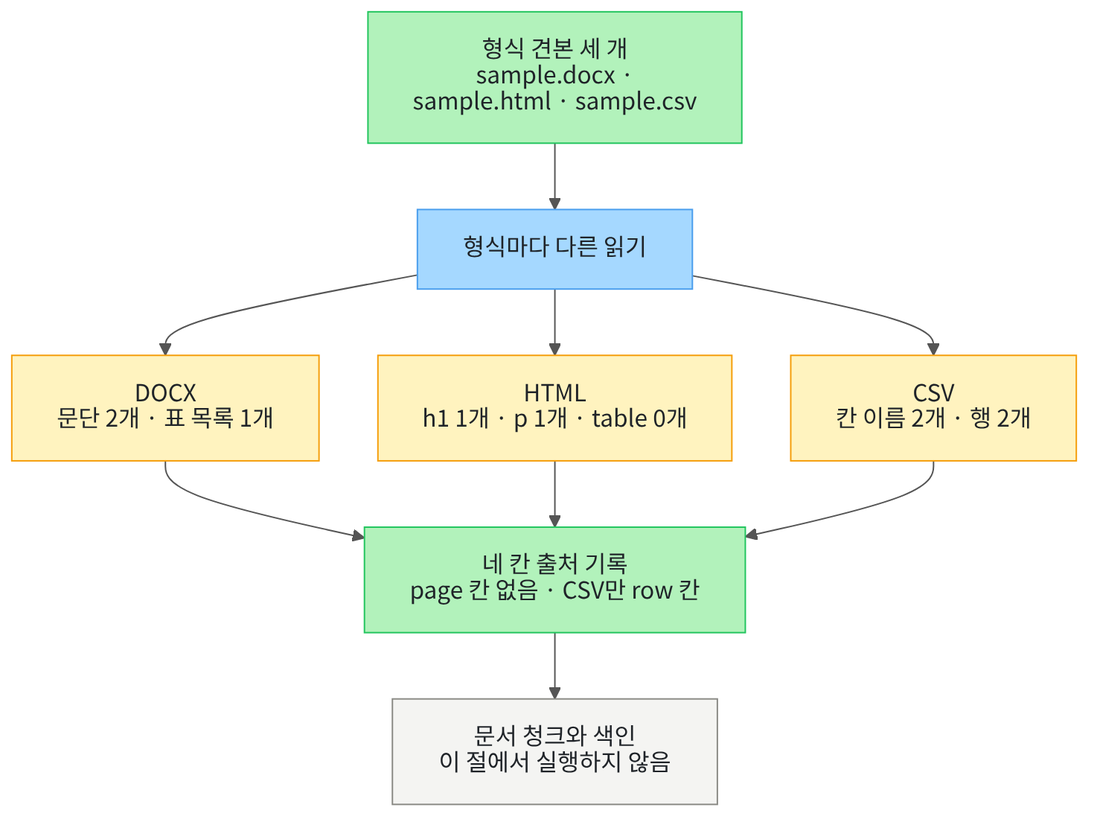

위에서 아래로 봅니다. 견본 세 개를 형식마다 다른 방법으로 읽으면 남는 구조 정보가 다릅니다.
가운데 노란 상자 세 개가 이 절에서 출력으로 확인할 값입니다.
읽고 난 뒤에는 세 형식이 모두 같은 모양의 출처 기록으로 모입니다.
맨 아래 회색 상자는 05~08절에서 할 일이고 이 절에서는 실행하지 않습니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01·02절에서 쓴 `Document`에 DOCX를 읽는 python-docx와 HTML을 읽는 beautifulsoup4를 더합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "python-docx==1.2.0" "beautifulsoup4==4.15.0" "langchain-core==1.6.2"
from importlib.metadata import version

print("python-docx:", version("python-docx"))
print("beautifulsoup4:", version("beautifulsoup4"))
print("langchain-core:", version("langchain-core"))

Note: you may need to restart the kernel to use updated packages.
python-docx: 1.2.0
beautifulsoup4: 4.15.0
langchain-core: 1.6.2


**결과 읽기** — 출력 줄은 `python-docx: 1.2.0`, `beautifulsoup4: 4.15.0`, `langchain-core: 1.6.2` 세 줄입니다.
준비물에 적은 기준 버전과 같습니다. CSV 읽기 도구는 Python에 들어 있어 따로 설치하지 않습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
`from docx import Document as DocxDocument` 줄은 DOCX 파일을 여는 클래스에 다른 이름을 붙입니다.
python-docx에도 `Document`가 있어서 LangChain의 `Document`와 이름이 겹치기 때문입니다.
Ch 4 01절에서 쓴 `import pandas as pd`와 같은 표기입니다.

In [2]:
# 파일 찾기·DOCX 읽기·HTML 읽기·CSV 읽기·문서 객체 만들기에 쓸 이름을 불러옵니다
import csv
import os
from pathlib import Path

from bs4 import BeautifulSoup
from docx import Document as DocxDocument
from langchain_core.documents import Document

## 2. 견본 세 개 찾기

01·02절과 같은 방법으로 프로젝트 맨 위 경로를 고릅니다.
후보 세 개를 차례로 확인하고, 있는 경로에서 멈춥니다.
이번에 찾는 폴더는 문서 모음이 아니라 이 챕터의 견본 폴더입니다.

실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [3]:
# 작업 폴더에서 본 프로젝트 맨 위 경로를 후보 세 개 가운데에서 고릅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch10-document-processing/fixtures"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 읽을 견본 세 개의 경로를 만듭니다.
세 파일은 한 문단짜리 안내문과 작은 표를 담은 아주 작은 파일입니다.
형식마다 무엇이 남는지 보는 것이 목적이라 내용은 짧게 두었습니다.

In [4]:
# 읽을 견본 세 개의 경로를 만들고 파일이 있는지 확인합니다
fixtures_path = root_path + "/labs/part3/ch10-document-processing/fixtures"
docx_path = fixtures_path + "/sample.docx"
html_path = fixtures_path + "/sample.html"
csv_path = fixtures_path + "/sample.csv"
print("DOCX 견본이 있는가:", os.path.exists(docx_path))
print("HTML 견본이 있는가:", os.path.exists(html_path))
print("CSV 견본이 있는가:", os.path.exists(csv_path))

DOCX 견본이 있는가: True
HTML 견본이 있는가: True
CSV 견본이 있는가: True


**결과 읽기** — 출력 세 줄이 모두 `True`입니다.
이 견본들은 01절 2절에서 확장자 다섯 가지를 셀 때 이름만 보았던 파일입니다.
나머지 두 개는 `.hwp`와 `.hwpx`이고 04절에서 읽습니다.

## 3. DOCX 문단 목록과 꾸밈 이름

파일 sample.docx를 열면 문단 목록을 얻습니다.
문단은 DOCX에서 글을 담는 기본 단위입니다.
문단마다 꾸밈 이름이 붙어 있어서 제목 문단과 본문 문단을 가를 수 있습니다.

실행 전에 예상합니다. 문단 두 개가 나오고 꾸밈 이름은 서로 다를 것입니다.

In [5]:
# DOCX 견본을 열어 문단 목록의 글과 꾸밈 이름을 봅니다
docx_file = DocxDocument(docx_path)
paragraph_texts = []
paragraph_styles = []
for paragraph in docx_file.paragraphs:
    paragraph_texts.append(paragraph.text)
    paragraph_styles.append(paragraph.style.name)
print("객체 이름:", type(docx_file).__name__)
print("문단 수:", len(docx_file.paragraphs))
print("문단 글:", paragraph_texts)
print("문단 꾸밈 이름:", paragraph_styles)

객체 이름: Document
문단 수: 2
문단 글: ['배송 안내', '제주 배송에는 이틀이 더 필요합니다.']
문단 꾸밈 이름: ['Heading 1', 'Normal']


**결과 읽기** — 출력 줄은 `문단 수: 2`입니다.
다음 줄 `문단 글: ['배송 안내', '제주 배송에는 이틀이 더 필요합니다.']`이 두 문단의 글입니다.
마지막 줄 `문단 꾸밈 이름: ['Heading 1', 'Normal']`을 보세요.
앞 문단은 제목이고 뒤 문단은 본문이라는 뜻입니다.

PDF에서는 이런 이름을 얻지 못했습니다. 글자와 자리만 있었기 때문입니다.
작성 도구가 남긴 이름이 있으면 나중에 제목을 기준으로 글을 나눌 수 있습니다.

## 4. 표는 다른 목록에 들어 있습니다

파일 sample.docx에는 표도 하나 있습니다.
그런데 표의 글은 문단 목록에 들어오지 않습니다.
표는 `docx_file.tables`라는 다른 목록에 들어 있습니다.

먼저 표의 한 행에서 칸의 글을 모으는 함수를 정의합니다.

In [6]:
# 표의 한 행을 받아 칸의 글을 순서대로 모아 목록으로 반환합니다
def read_row_values(table_row):
    values = []
    for cell in table_row.cells:
        values.append(cell.text)
    return values

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

한 행 안에서 칸은 `table_row.cells`로 얻고, 칸의 글은 `cell.text`로 읽습니다.
문단에서 글을 읽을 때 쓴 `paragraph.text`와 같은 표기입니다.

다음 셀은 표 목록을 열어 표의 수와 행·칸을 봅니다.

In [7]:
# 문단 목록과 따로 있는 표 목록을 열어 행과 칸을 봅니다
docx_tables = docx_file.tables
first_docx_table = docx_tables[0]
docx_header = read_row_values(first_docx_table.rows[0])
docx_first_row = read_row_values(first_docx_table.rows[1])
print("표 목록의 표 수:", len(docx_tables))
print("첫 표의 행 수:", len(first_docx_table.rows))
print("머리글 행:", docx_header)
print("첫 행:", docx_first_row)

표 목록의 표 수: 1
첫 표의 행 수: 2
머리글 행: ['지역', '추가 일수']
첫 행: ['제주', '2일']


**결과 읽기** — 출력 줄은 `표 목록의 표 수: 1`과 `첫 표의 행 수: 2`입니다.
머리글 한 행에 값 한 행을 더해 두 행입니다.
다음 줄 `머리글 행: ['지역', '추가 일수']`와 `첫 행: ['제주', '2일']`이 칸의 글입니다.

3절 출력의 `문단 글`을 다시 보세요. 표에만 있는 말 `추가 일수`가 거기에 없습니다.
문단 목록만 읽으면 표가 통째로 빠집니다. 10절에서 그 결과를 확인합니다.

## 5. HTML 태그 이름으로 고르기

파일 sample.html은 태그로 감싼 글입니다.
태그는 글을 감싸 그 글의 종류를 알려 주는 이름입니다.
제목은 `h1` 태그, 본문 문단은 `p` 태그로 감싸여 있습니다.

메서드 `find_all(태그 이름)`은 그 이름의 태그를 문서 순서대로 모아 목록으로 반환합니다.
Ch 4 05절에서 HTML을 읽을 때 쓴 것과 같은 라이브러리입니다.

In [8]:
# HTML 견본을 읽어 태그 나무를 만들고 태그 종류마다 개수를 셉니다
with open(html_path, encoding="utf-8") as html_file:
    html_source = html_file.read()
soup = BeautifulSoup(html_source, "html.parser")
title_tags = soup.find_all("h1")
body_tags = soup.find_all("p")
table_tags = soup.find_all("table")
style_tags = soup.find_all("style")
print("객체 이름:", type(soup).__name__)
print("h1 태그 수:", len(title_tags))
print("p 태그 수:", len(body_tags))
print("table 태그 수:", len(table_tags))
print("style 태그 수:", len(style_tags))

객체 이름: BeautifulSoup
h1 태그 수: 1
p 태그 수: 1
table 태그 수: 0
style 태그 수: 1


**결과 읽기** — 출력 줄은 `h1 태그 수: 1`과 `p 태그 수: 1`입니다.
다음 줄 `table 태그 수: 0`을 보세요. 이 견본에는 표가 없습니다.
마지막 줄 `style 태그 수: 1`은 화면 표시를 정하는 태그입니다.

형식마다 표가 들어 있는 자리가 다릅니다.
DOCX에서는 표 목록에 들어 있었고, HTML에서는 `table` 태그로 찾습니다.
같은 방법으로 셋을 다 찾을 수는 없습니다.

다음 셀은 고를 태그 이름 목록을 받아 그 태그의 글을 모으는 함수를 정의합니다.

In [9]:
# 태그 나무와 고를 태그 이름 목록을 받아 그 태그의 글을 모아 반환합니다
def pick_tag_texts(tag_tree, wanted_tags):
    picked = []
    for tag in tag_tree.find_all(wanted_tags):
        picked.append(tag.get_text(" ", strip=True))
    return picked

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

메서드 `get_text(" ", strip=True)`는 태그 안의 글을 꺼냅니다.
첫 인자는 안쪽 태그가 여러 개일 때 사이에 넣을 글이고, `strip=True`는 앞뒤 빈칸을 없앱니다.

다음 셀은 제목과 본문을 함께 골라 태그 이름과 글을 봅니다.

In [10]:
# 제목 태그와 본문 태그를 함께 골라 글과 태그 이름을 봅니다
wanted_tags = ["h1", "p"]
picked_tags = soup.find_all(wanted_tags)
picked_texts = pick_tag_texts(soup, wanted_tags)
first_tag_name = picked_tags[0].name
second_tag_name = picked_tags[1].name
print("고를 태그 목록:", wanted_tags)
print("고른 글:", picked_texts)
print("첫 글의 태그 이름:", first_tag_name)
print("둘째 글의 태그 이름:", second_tag_name)

고를 태그 목록: ['h1', 'p']
고른 글: ['반품 안내', '수령 후 7일 이내 신청합니다.']
첫 글의 태그 이름: h1
둘째 글의 태그 이름: p


**결과 읽기** — 출력 줄 `고른 글: ['반품 안내', '수령 후 7일 이내 신청합니다.']`이 골라낸 두 글입니다.
다음 두 줄 `첫 글의 태그 이름: h1`과 `둘째 글의 태그 이름: p`가 그 글의 종류입니다.
`style` 태그도 하나 있었지만 고를 목록에 넣지 않아 그 글은 들어오지 않았습니다.

형식 DOCX의 꾸밈 이름과 같은 일을 태그 이름이 합니다.
글을 이어 붙이기 전에 어느 글이 제목인지 알 수 있습니다.

## 6. CSV는 첫 줄이 칸 이름입니다

파일 sample.csv는 파일 전체가 표 하나입니다.
첫 줄에 칸 이름이 있고 그 아래 줄마다 값이 있습니다.
클래스 `csv.DictReader`는 첫 줄을 칸 이름으로 삼아 아래 줄을 딕셔너리로 만듭니다.

인자 `newline=""`는 줄바꿈 처리를 `csv`에 맡기는 표시입니다.
CSV 설명서가 파일을 열 때 이렇게 쓰라고 적어 두었습니다.

In [11]:
# CSV 견본을 열어 첫 줄의 칸 이름과 그 아래 행을 읽습니다
with open(csv_path, encoding="utf-8", newline="") as csv_file:
    reader = csv.DictReader(csv_file)
    csv_header = reader.fieldnames
    csv_rows = []
    for row in reader:
        csv_rows.append(row)
print("칸 이름:", csv_header)
print("행 수:", len(csv_rows))
print("첫 행:", csv_rows[0])
print("첫 행의 자료형:", type(csv_rows[0]).__name__)

칸 이름: ['상품', '보관']
행 수: 2
첫 행: {'상품': '쿠키', '보관': '실온'}
첫 행의 자료형: dict


**결과 읽기** — 출력 줄은 `칸 이름: ['상품', '보관']`과 `행 수: 2`입니다.
칸 이름 줄은 행으로 세지 않습니다.
다음 줄 `첫 행: {'상품': '쿠키', '보관': '실온'}`을 보세요.
마지막 줄 `첫 행의 자료형: dict`가 그 모양입니다.

02절에서는 표의 한 행이 칸의 글만 담은 목록이었습니다.
그때는 칸 번호로 머리글의 짝을 찾아야 했습니다.
클래스 `csv.DictReader`는 그 짝을 미리 지어 줍니다. 형식이 칸 이름을 첫 줄에 담고 있기 때문입니다.

## 7. 한 행을 한 줄 글로 만들기

02절에서 만든 함수 두 개를 같은 코드로 가져옵니다.
앞 함수는 머리글 하나와 칸 하나를 짝지어 글을 만듭니다.
뒤 함수는 그 함수를 칸마다 불러 한 행을 한 줄로 만듭니다.

In [12]:
# 머리글 하나와 칸 하나를 받아 「머리글: 값」 꼴로 짝지은 글을 만들어 반환합니다(02절 5절과 같은 코드)
def make_cell_text(label, cell):
    value = cell
    if value == "":
        value = "(값 없음)"
    return label + ": " + value

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

값이 없는 칸은 `(값 없음)`으로 바꿔 적습니다. 02절에서 정한 대로입니다.
이 절의 견본 세 개에는 값이 없는 칸이 없어서 그 글은 나오지 않습니다.

In [13]:
# 머리글 행과 표의 한 행을 받아 칸마다 머리글을 붙인 한 줄 글을 만들어 반환합니다(02절 5절과 같은 코드)
def make_row_text(header_row, row):
    row_text = ""
    cell_number = 0
    for cell in row:
        cell_text = make_cell_text(header_row[cell_number], cell)
        if row_text != "":
            row_text = row_text + " / "
        row_text = row_text + cell_text
        cell_number = cell_number + 1
    return row_text

**결과 읽기** — 이 셀도 함수를 만들기만 하므로 출력이 없습니다.

이 함수는 머리글 행과 값 행을 목록으로 받습니다.
그래서 DOCX 표의 행에도 쓸 수 있고, CSV 행의 값을 목록으로 꺼내면 거기에도 쓸 수 있습니다.

다음 셀은 두 형식의 행을 같은 함수에 넣습니다.

In [14]:
# 같은 함수로 DOCX 표의 한 행과 CSV의 두 행을 한 줄 글로 만듭니다
docx_row_text = make_row_text(docx_header, docx_first_row)
csv_row_texts = []
for row in csv_rows:
    values = []
    for column in csv_header:
        values.append(row[column])
    row_text = make_row_text(csv_header, values)
    csv_row_texts.append(row_text)
print("DOCX 표의 한 행:", docx_row_text)
print("CSV 첫 행:", csv_row_texts[0])
print("CSV 둘째 행:", csv_row_texts[1])

DOCX 표의 한 행: 지역: 제주 / 추가 일수: 2일
CSV 첫 행: 상품: 쿠키 / 보관: 실온
CSV 둘째 행: 상품: 케이크 / 보관: 냉장


**결과 읽기** — 출력 줄 `DOCX 표의 한 행: 지역: 제주 / 추가 일수: 2일`이 첫 결과입니다.
다음 두 줄 `CSV 첫 행: 상품: 쿠키 / 보관: 실온`과 `CSV 둘째 행: 상품: 케이크 / 보관: 냉장`이 CSV 결과입니다.

세 줄 모두 값 앞에 칸 이름이 붙어 있습니다.
검색된 글만 보고도 그 값이 무엇의 값인지 읽을 수 있는 모양입니다.

## 8. 쪽 번호가 없는 형식의 출처 기록

01절 `make_source_record()`는 쪽 번호를 반드시 받았습니다.
이 절의 세 형식에는 쪽이라는 것이 없습니다. 세 파일 모두 한 쪽이라고 말할 수도 없습니다.
그래서 `page` 칸을 넣지 않고 네 칸만 적습니다.

다음 셀은 01절 함수에서 쪽 번호 칸만 뺀 함수를 정의합니다.

In [15]:
# 파일 경로와 읽은 방법 이름을 받아 쪽 번호가 없는 네 칸 출처 기록을 만들어 반환합니다
def make_unit_record(file_path, parser):
    path_object = Path(file_path)
    suffix = path_object.suffix
    file_type = suffix.replace(".", "").lower()
    record = {"doc_id": path_object.stem, "source": path_object.name,
              "file_type": file_type, "parser": parser}
    return record

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

네 칸 이름은 01·02절과 같습니다. `doc_id`·`source`·`file_type`·`parser`입니다.
`parser` 칸에 적을 이름이 이 절에서 세 개 늘어납니다.
실습 폴더 모듈이 쓰는 이름과 같은 글로 적습니다.

다음 셀은 형식마다 기록을 만들고 CSV 기록에만 칸 하나를 더합니다.
형식 CSV는 행마다 따로 담을 수 있어서 파일 안의 자리를 적을 수 있습니다.

In [16]:
# 형식마다 네 칸 기록을 만들고 CSV 기록에만 행 번호 칸을 더합니다
docx_record = make_unit_record(docx_path, "python-docx")
html_record = make_unit_record(html_path, "beautifulsoup")
csv_record = make_unit_record(csv_path, "csv.DictReader")
csv_record["row"] = 2
print("DOCX 기록:", docx_record)
print("HTML 기록:", html_record)
print("CSV 기록:", csv_record)
print("DOCX 기록에 page 칸이 있는가:", "page" in docx_record)
print("세 기록의 doc_id:", docx_record["doc_id"], html_record["doc_id"], csv_record["doc_id"])

DOCX 기록: {'doc_id': 'sample', 'source': 'sample.docx', 'file_type': 'docx', 'parser': 'python-docx'}
HTML 기록: {'doc_id': 'sample', 'source': 'sample.html', 'file_type': 'html', 'parser': 'beautifulsoup'}
CSV 기록: {'doc_id': 'sample', 'source': 'sample.csv', 'file_type': 'csv', 'parser': 'csv.DictReader', 'row': 2}
DOCX 기록에 page 칸이 있는가: False
세 기록의 doc_id: sample sample sample


**결과 읽기** — 출력 줄 `DOCX 기록:` 뒤에 `{'doc_id': 'sample', 'source': 'sample.docx', 'file_type': 'docx', 'parser': 'python-docx'}`가 보입니다.
`HTML 기록:` 줄과 `CSV 기록:` 줄에서는 `file_type`과 `parser` 값이 형식마다 다릅니다.
CSV 기록에는 `'row': 2`가 하나 더 있습니다. 파일의 둘째 줄에서 온 값이라는 뜻입니다.

다음 줄 `DOCX 기록에 page 칸이 있는가: False`를 보세요.
01·02절 `make_source_mark()`는 기록의 `page` 칸을 읽어 `[E01 p.2]`를 만들었습니다.
이 절 기록에는 그 칸이 없어서 그 함수를 쓰지 않습니다.

마지막 줄 `세 기록의 doc_id: sample sample sample`도 보세요.
세 파일의 이름 앞부분이 모두 `sample`이라서 문서 이름이 같습니다.
형식이 다른데 문서 이름이 같으면 검색 결과에서 가를 수 없습니다.

다음 셀은 이 절 기록을 읽는 출처 표시 함수를 정의합니다.

In [17]:
# 문서 청크 하나를 받아 파일 형식과 자리 칸을 넣은 출처 표시를 만들어 반환합니다
def make_unit_mark(chunk):
    doc_id = chunk.metadata["doc_id"]
    file_type = chunk.metadata["file_type"]
    unit_mark = f"[{doc_id} {file_type}]"
    if "row" in chunk.metadata:
        row_number = chunk.metadata["row"]
        unit_mark = f"[{doc_id} {file_type} row.{row_number}]"
    return unit_mark

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

기록에 `row` 칸이 있으면 그 번호까지 붙입니다. 없으면 파일 형식까지만 붙입니다.
쪽 번호 자리에 형식 이름을 넣어 PDF의 `[E01 p.2]`와 헷갈리지 않게 합니다.

다음 셀은 CSV 행마다 `Document` 하나를 만듭니다.

In [18]:
# CSV 행마다 Document 하나를 만들고 행 번호가 붙은 출처 표시를 봅니다
row_documents = []
row_number = 2
for row_text in csv_row_texts:
    row_record = make_unit_record(csv_path, "csv.DictReader")
    row_record["row"] = row_number
    row_document = Document(page_content=row_text, metadata=row_record)
    row_documents.append(row_document)
    row_number = row_number + 1
print("행 Document 수:", len(row_documents))
print("첫 행의 출처 표시:", make_unit_mark(row_documents[0]))
print("둘째 행의 출처 표시:", make_unit_mark(row_documents[1]))
print("둘째 행의 기록:", row_documents[1].metadata)

행 Document 수: 2
첫 행의 출처 표시: [sample csv row.2]
둘째 행의 출처 표시: [sample csv row.3]
둘째 행의 기록: {'doc_id': 'sample', 'source': 'sample.csv', 'file_type': 'csv', 'parser': 'csv.DictReader', 'row': 3}


**결과 읽기** — 출력 줄은 `행 Document 수: 2`입니다. 칸 이름 줄은 담지 않았습니다.
다음 두 줄 `첫 행의 출처 표시: [sample csv row.2]`와 `둘째 행의 출처 표시: [sample csv row.3]`이 표시입니다.
행 번호를 2부터 센 까닭은 파일의 첫 줄이 칸 이름 줄이기 때문입니다.
실습 폴더 모듈도 같은 번호를 씁니다.

마지막 줄 `둘째 행의 기록:` 뒤에 `{'doc_id': 'sample', 'source': 'sample.csv', 'file_type': 'csv', 'parser': 'csv.DictReader', 'row': 3}`가 보입니다.
칸이 다섯 개인데 마지막 칸 이름이 `page`가 아니라 `row`입니다.

## 9. 값 하나만 바꿔 보기

바꾸는 값은 고를 태그 목록 하나입니다. `["h1", "p"]`에서 `["p"]`로 바꿉니다.
함수는 고치지 않고 인자만 바꿉니다.

실행 전에 예상합니다. 제목 글이 빠지고 본문 글 하나만 남을 것입니다.

In [19]:
# 고를 태그 목록에서 h1을 빼고 같은 함수를 다시 부릅니다
changed_tags = ["p"]
changed_texts = pick_tag_texts(soup, changed_tags)
print("바꾼 태그 목록:", changed_tags)
print("고른 글 수:", len(changed_texts))
print("고른 글:", changed_texts)

바꾼 태그 목록: ['p']
고른 글 수: 1
고른 글: ['수령 후 7일 이내 신청합니다.']


**결과 읽기** — 출력 줄은 `고른 글 수: 1`입니다. 5절에서는 두 개였습니다.
다음 줄 `고른 글: ['수령 후 7일 이내 신청합니다.']`에서 제목 `반품 안내`가 빠졌습니다.

고를 태그 목록이 검색에 들어갈 글의 범위를 정합니다.
목록을 좁히면 메뉴나 바닥글을 덜 담지만 제목도 함께 빠질 수 있습니다.
어느 목록이 늘 낫다고 정하지는 않습니다. 이번에 읽은 견본은 태그 세 종류짜리 한 건입니다.

## 10. 일부러 실패해 보기

이제 DOCX 견본을 하나의 `Document`로 담습니다.
Before 셀은 문단 목록만 이어 붙입니다. 표 목록은 읽지 않습니다.
오류는 나지 않습니다. 문단 목록만으로도 글이 만들어지기 때문입니다.

In [20]:
# DOCX 문단 목록만 줄바꿈으로 이어 붙여 본문 글 하나를 만듭니다
before_text = ""
for paragraph_text in paragraph_texts:
    if before_text != "":
        before_text = before_text + "\n"
    before_text = before_text + paragraph_text
print("이어 붙인 글자 수:", len(before_text))

이어 붙인 글자 수: 26


**결과 읽기** — 출력 줄은 `이어 붙인 글자 수: 26`입니다.
문단 두 개의 글자 수에 줄바꿈 하나를 더한 수입니다.

다음 셀은 이 글로 `Document`를 만들고 표의 값이 들어 있는지 봅니다.
찾는 말은 4절에서 본 표 머리글 `추가 일수`입니다.

In [21]:
# 이어 붙인 글로 Document를 만들고 표의 값이 들어 있는지 봅니다
before_record = make_unit_record(docx_path, "python-docx")
before_document = Document(page_content=before_text, metadata=before_record)
table_word = "추가 일수"
print("본문 글자 수:", len(before_document.page_content))
print("출처 표시:", make_unit_mark(before_document))
print("표 머리글이 본문에 있는가:", table_word in before_document.page_content)
print("본문:")
print(before_document.page_content)

본문 글자 수: 26
출처 표시: [sample docx]
표 머리글이 본문에 있는가: False
본문:
배송 안내
제주 배송에는 이틀이 더 필요합니다.


**결과 읽기** — 출력 줄은 `본문 글자 수: 26`입니다.
다음 줄 `출처 표시: [sample docx]`도 만들어졌습니다.
기록도 본문도 모양이 갖춰져 있어서 겉으로는 다 읽은 것처럼 보입니다.

그런데 다음 줄은 `표 머리글이 본문에 있는가: False`입니다.
`본문:` 라벨 줄 아래 두 줄을 보세요. 문단 두 개만 있고 표의 값이 없습니다.
4절에서 본 `['지역', '추가 일수']`와 `['제주', '2일']`이 모두 빠졌습니다.

## 11. 고쳐서 다시 실행하기

표 목록의 행도 한 줄 글로 만들어 본문에 더합니다.
7절 함수를 그대로 쓰고, 머리글 행은 담지 않습니다.
칸 이름은 이미 값 앞에 붙기 때문입니다.

In [22]:
# 표 목록의 행에 머리글을 붙여 문단 글 뒤에 더합니다
after_text = before_text
row_number = 1
for table_row in first_docx_table.rows:
    if row_number > 1:
        row_values = read_row_values(table_row)
        row_text = make_row_text(docx_header, row_values)
        after_text = after_text + "\n" + row_text
    row_number = row_number + 1
print("더한 뒤 글자 수:", len(after_text))

더한 뒤 글자 수: 45


**결과 읽기** — 출력 줄은 `더한 뒤 글자 수: 45`입니다. 10절의 26자보다 늘었습니다.
변수 `row_number`가 1인 첫 행은 머리글 행이라 건너뛰었습니다.
그래서 늘어난 줄은 값 한 행에서 온 한 줄입니다.

다음 셀은 표까지 담은 글로 `Document`를 다시 만듭니다.

In [23]:
# 표까지 담은 글로 Document를 만들고 표의 값이 들어 있는지 다시 봅니다
after_record = make_unit_record(docx_path, "python-docx")
after_document = Document(page_content=after_text, metadata=after_record)
print("본문 글자 수:", len(after_document.page_content))
print("표 머리글이 본문에 있는가:", table_word in after_document.page_content)
print("본문:")
print(after_document.page_content)
assert table_word in after_document.page_content

본문 글자 수: 45
표 머리글이 본문에 있는가: True
본문:
배송 안내
제주 배송에는 이틀이 더 필요합니다.
지역: 제주 / 추가 일수: 2일


**결과 읽기** — 출력 줄 `표 머리글이 본문에 있는가: True`로 바뀌었습니다. `assert`도 통과했습니다.

`본문:` 라벨 줄 아래 세 줄을 보세요.
마지막 줄 `지역: 제주 / 추가 일수: 2일`이 표에서 온 글입니다.
출처 기록은 두 실행이 같습니다. 문단과 표를 한 `Document`에 담았기 때문입니다.

표를 행마다 따로 담을지 한 `Document`에 함께 담을지는 정해져 있지 않습니다.
이번에는 견본이 두 행짜리 표 하나여서 함께 담았습니다.

## 12. 정리

1. 형식마다 남는 구조 정보가 다릅니다. 차례로 DOCX 문단의 꾸밈 이름, HTML 태그 이름, CSV 첫 줄의 칸 이름입니다.
2. 표가 들어 있는 자리도 형식마다 다릅니다. 차례로 DOCX 표 목록, HTML `table` 태그, CSV 파일 전체입니다.
3. 쪽이 없는 형식은 `page` 칸을 넣지 않고 네 칸만 적습니다. CSV만 `row` 칸을 하나 더합니다.
4. 문단 목록만 읽으면 표가 통째로 빠졌습니다. 표 목록의 행을 더해 26자에서 45자가 되었습니다.

다음 04절에서는 HWP와 HWPX를 가릅니다. 이름이 비슷하지만 파일 안의 모양이 다릅니다.
HWPX 견본을 열어 압축 파일 속 XML을 직접 보고, 그때도 같은 칸 이름에 담습니다.